# Overview

##### This is the a report for the UEFA Champions League Final 2021/2022 (Liverpool vs Real Madred) players shots and xGs during the match.

## Import Libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from highlight_text import fig_text
import numpy as np

## Read the csv file data
#### The dataset contains:
- **Minute**: The minute when the shot happened.
- **Player**: The player who took the shot.
- **Squad**: The team (Real Madrid or Liverpool).
- **xG**: Expected Goals; estimates the likelihood that a shot will result in a goal.
- **PSxG**: Post-Shot Expected Goals; estimates the likelihood that a shot on target will become a goal.
- **Outcome**: The result of the shot (e.g., saved, blocked, or goal).
- **Distance**: The distance from which the shot was taken.
- **Body Part**: The body part used to take the shot.
- **Notes**: Additional details about the shot.
- **Assist Player**: The player who provided the assist.
- **Assist Event**: The event that led to the assist.
- **Second Assist Player**: The player involved in the second assist.
- **Second Assist Event**: The event that led to the second assist.

In [4]:
shots_df = pd.read_csv('shots_table.csv')
shots_df.head()

,Minute,Player,Squad,xG,PSxG,Outcome,Distance,Body Part,Notes,Assist Player,Assist Event,Second Assist Player,Second Assist Event
0,16,Mohamed Salah,Liverpool,0.29,0.32,Saved,13,Right Foot,NaN,Jordan Henderson,Pass (Live),Thiago Alcântara,Pass (Live)
1,16,Luis Díaz,Liverpool,0.07,NaN,Blocked,15,Left Foot,NaN,Sadio Mané,Pass (Live),Mohamed Salah,Shot
2,17,Thiago Alcântara,Liverpool,0.09,NaN,Blocked,15,Left Foot,NaN,Andrew Robertson,Pass (Live),Sadio Mané,Pass (Live)
3,17,Mohamed Salah,Liverpool,0.09,0.13,Saved,15,Left Foot,NaN,Andrew Robertson,Pass (Live),Sadio Mané,Pass (Live)
4,19,Trent Alexander-Arnold,Liverpool,0.09,0.10,Off Target,29,Right Foot,NaN,Mohamed Salah,Pass (Live),Andrew Robertson,Pass (Live)


In [6]:
shots_df.columns

Index(['Minute', 'Player', 'Squad', 'xG', 'PSxG', 'Outcome', 'Distance',
       'Body Part', 'Notes', 'Assist Player', 'Assist Event',
       'Second Assist Player', 'Second Assist Event'],
      dtype='str')

## Extract only wanted column for this report

In [7]:
xg_stats = shots_df[['Minute', 'Player', 'Squad', 'xG', 'Outcome']]
xg_stats.head(3)

,Minute,Player,Squad,xG,Outcome
0,16,Mohamed Salah,Liverpool,0.29,Saved
1,16,Luis Díaz,Liverpool,0.07,Blocked
2,17,Thiago Alcântara,Liverpool,0.09,Blocked


## Calculate the cumulative xG
This code calculates a running total of expected goals (xG) separately for each team. The `groupby('Squad')` operation groups the shots by team, and `cumsum()` adds each shot’s xG to that team’s previous total in row order. The result is stored in a new `Cumulative_xG` column. Finally, `head()` displays the first five rows.

In [14]:
# Calculated the cumulative xG for each team
xg_stats['Cumulative_xG'] = xg_stats.groupby('Squad')['xG'].cumsum()
xg_stats.head()

,Minute,Player,Squad,xG,Outcome,Cumulative_xG
0,16,Mohamed Salah,Liverpool,0.29,Saved,0.29
1,16,Luis Díaz,Liverpool,0.07,Blocked,0.36
2,17,Thiago Alcântara,Liverpool,0.09,Blocked,0.45
3,17,Mohamed Salah,Liverpool,0.09,Saved,0.54
4,19,Trent Alexander-Arnold,Liverpool,0.09,Off Target,0.63


## Cleaning
##### Drop the null values

In [8]:
xg_stats = xg_stats.dropna(subset=['xG'])
xg_stats.head(3)

,Minute,Player,Squad,xG,Outcome
0,16,Mohamed Salah,Liverpool,0.29,Saved
1,16,Luis Díaz,Liverpool,0.07,Blocked
2,17,Thiago Alcântara,Liverpool,0.09,Blocked


This code creates a `Half` column in `xg_stats`. It assigns `1` to shots in the first half (minute 45 or earlier) and `2` to shots after minute 45. For added-time values such as `"90+2"`, it checks the minute before the `+`. The final line displays the last five rows to verify the result.

**Note:** The `Minute` column contains numeric values as well as added-time strings, so calling `.split()` directly may raise an error. Convert values to strings first, for example with `xg_stats['Minute'].astype(str)`.

In [ ]:
xg_stats['Half'] = xg_stats['Minute'].apply(lambda x: 1 if int(x.split('+')[0]) <= 45 else 2)
xg_stats.head(3)

,Minute,Player,Squad,xG,Outcome,Cumulative_xG,Half
22,75,Roberto Firmino,Liverpool,0.04,Blocked,1.43,2
23,85,Mohamed Salah,Liverpool,0.04,Saved,1.47,2
24,85,Diogo Jota,Liverpool,0.04,Saved,1.51,2
25,88,Naby Keïta,Liverpool,0.03,Blocked,1.54,2
26,90+2,Eduardo Camavinga,Real Madrid,0.03,Blocked,0.78,2


In [9]:
xg_stats['Minute'] = xg_stats['Minute'].apply(lambda x: sum([int(y) for y in x.split('+')]))
xg_stats.head(3)

,Minute,Player,Squad,xG,Outcome
0,16,Mohamed Salah,Liverpool,0.29,Saved
1,16,Luis Díaz,Liverpool,0.07,Blocked
2,17,Thiago Alcântara,Liverpool,0.09,Blocked


# Cumulative xG Plot (Split by Half): Real Madrid vs Liverpool, 2021/22 UEFA Champions League Final


## 1. What the plot shows

This is a **cumulative expected goals (xG) timeline** for the final, drawn separately for each half.

- **xG (expected goals)** is the probability that a shot becomes a goal, based on factors such as distance, angle and the type of chance.
- **Cumulative xG** is the running total of those values. Each time a team takes a shot, its line steps up by that shot's xG.
- A **flat line** means no new shots. A **tall step** means one high-quality chance. **Several small steps** mean several low-quality chances.

The chart is split into a **1st half** (minutes 0 to 45) on the left and a **2nd half** (minutes 45 to about 95) on the right, with a visible **gap around half-time**.

## 2. How to read it

| Element | Meaning |
|---|---|
| **X-axis** | Match minute, with a tick every 5 minutes up to 95. |
| **Y-axis** | Cumulative xG, with ticks chosen automatically (0.0 to 1.6 here). There is no y-axis label in this version. |
| **Red line** | Liverpool (`'red'`). |
| **Gold line** | Real Madrid (`'gold'`). |
| **Title colours** | "Real Madrid" in gold and "Liverpool" in red act as the legend, since the plot has no legend box. |
| **"1st Half" / "2nd Half" labels** | Sit below the x-axis at minutes 22.5 and 70. |
| **Gap near minute 37 to 45** | The first-half lines stop at each team's last first-half shot, so the lines do not meet the second-half lines at minute 45 (see section 5). |

## 3. What the chart tells us

The values below are approximate readings from the chart.

### Overall picture

Liverpool created clearly more chance quality, finishing at roughly **1.5 xG** against Real Madrid's roughly **0.8 xG**. Liverpool's red line sits above the gold line for almost the entire match.

### First half

- **Liverpool** started creating chances at about the **16th minute**. A rapid series of steps between minutes 16 and 20 took the total from 0 to about 0.73, followed by smaller steps around minutes 33 and 36 to 37. Liverpool's first-half total was about **0.9 xG**.
- **Real Madrid** created almost nothing. The gold line stays at **0.0** until a very small step around minute 43 (about 0.01), so Madrid ended the half with practically no accumulated xG.

### Second half

- **Liverpool** kept adding steadily, with steps at about minutes 54 to 55, 64, 73 to 75, and 85 to 88. The total rose from about 0.9 to about **1.5**, built from many smaller chances.
- **Real Madrid** had a small step at about minute 56, then a **large jump at about minute 59**, from about 0.05 to about 0.75. This single chance makes up almost all of Madrid's total xG. It lines up with the goal Real Madrid scored in the 59th minute, which won the match 1-0.
- After that jump the gold line stays flat until the end, with only a tiny step near minute 92.

### Key takeaway

Liverpool created more chances and more total xG, but Real Madrid scored from its one big chance. A lower xG total does not mean a team was lucky to win, and one high-value shot can outweigh many smaller ones.

## 4. How the code builds the plot

The code assumes a DataFrame called `xg_stats` with one row per shot and these columns: `Squad`, `Minute`, `xG`, `Outcome`, `Cumulative_xG`, and `Half`.

For each team, the loop does the following:

1. **Filters** the shots for that team.
2. **Adds a starting row** at minute 0 with `Cumulative_xG = 0` and `Half = 1`, so each line begins at the origin even if the team's first shot comes late.
3. **Rebuilds the table** in three parts, in this order:
   - the team's first-half rows (including the starting row),
   - one **synthetic row at minute 45** with `Half = 2` and `Cumulative_xG` equal to the last first-half value (the half-time total),
   - the team's second-half rows.
4. **Plots each half separately** (`for half in team_df['Half'].unique()`) with `drawstyle='steps-post'`, which holds each value flat until the next shot and then jumps. Both halves use the team's colour (`'red'` for Liverpool, `'gold'` for Real Madrid).

Formatting steps:

- `set_xticks` places a tick every 5 minutes from 0 to 95.
- `ax.text` adds the "1st Half" and "2nd Half" labels below the axis (y = -0.3).
- The top and right spines are hidden.
- `fig_text` (from the `highlight_text` library) writes the title with each team name in its own colour using `highlight_textprops`.

### Why there is a gap at half-time

The synthetic row at minute 45 is labelled `Half = 2`, so it becomes the **start of the second-half line**, not the end of the first-half line. The first-half line therefore stops at each team's last first-half shot (about minute 37 for Liverpool and about minute 43 for Real Madrid), and the second-half line begins at minute 45 at the half-time total. That is what creates the visible break.

## 5. Things worth noticing or improving

- **Half-time gap.** To draw a continuous line, add the minute-45 row to the first half as well (as an end point) and also to the second half (as a start point). Alternatively, plot the two halves in a single series.
- **Lines stop at the last shot.** Liverpool's line ends at about minute 88 and Real Madrid's at about 92, not at the final whistle. Adding a final point at full time would extend both lines to the end.
- **No y-axis label.** Add `ax.set_ylabel('Cumulative xG')`, since a reader cannot otherwise tell what the vertical axis measures.
- **No legend.** The colours are explained only by the title text, which works here but is easy to miss. The `label=team` argument is set, but `ax.legend()` is never called. If you do call it, the label is applied to both halves, so each team would appear twice. Label only one half per team.
- **Assumes sorted data.** The code uses `.iloc[-1]` to find the half-time total, which only works if `xg_stats` is already sorted by minute within each half. Add `.sort_values('Minute')` to be safe.
- **Repeated index labels.** The new rows are created with `index=[0]`, so the combined DataFrame has duplicate index values. This does not affect the plot, but `ignore_index=True` in `pd.concat` would be tidier.
- **Stoppage time.** If first-half shots can occur after minute 45 (added time), they would be placed after the synthetic minute-45 row, so check how added time is stored in `Minute`.
- **Mark the goals.** Adding a marker where a goal was scored would make the large steps, such as the one at minute 59, easier to interpret.


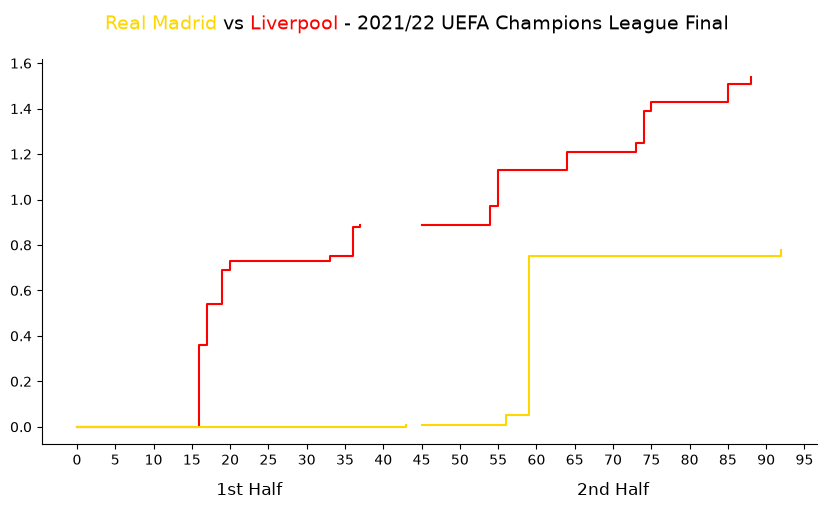

In [57]:
fig, ax = plt.subplots(figsize=(10, 5))

liverpool_color = 'red'
realmadred_color = 'gold'

for team in xg_stats['Squad'].unique():
    team_df = xg_stats[xg_stats['Squad'] == team]

    team_df = pd.concat(
            [pd.DataFrame({
                'Squad': team, 
                'Minute': 0,
                'xG': 0,
                'Outcome': '',
                'Cumulative_xG': 0,
                'Half': 1},
                index=[0]), 
            team_df]
        )

    team_df = pd.concat(
            [team_df[team_df['Half'] == 1],
            pd.DataFrame({
                'Squad': team, 
                'Minute': 45, 
                'xG': 0, 
                'Outcome': '', 
                'Cumulative_xG': team_df[team_df['Half'] == 1]['Cumulative_xG'].iloc[-1], 
                'Half': 2}, 
                index=[0]),
            team_df[team_df['Half'] == 2]]
        )

    for half in team_df['Half'].unique():
        half_df = team_df[team_df['Half'] == half]
        ax.plot(
            half_df['Minute'],
            half_df['Cumulative_xG'],
            label=team,
            drawstyle='steps-post',
            c = liverpool_color if team == 'Liverpool' else realmadred_color
        )
ax.set_xticks([i for i in range(0, 100, 5)])
ax.text(22.5, -.3, '1st Half', ha='center', fontsize=12)
ax.text(70  , -.3, '2nd Half', ha='center', fontsize=12)
ax.spines['right'].set_visible(False) 
ax.spines['top'].set_visible(False) 


fig_text(
    .5,
    .95,
    '<Real Madrid> vs <Liverpool> - 2021/22 UEFA Champions League Final',
    fontsize=14,
    ha='center',
    va='center',
    ax=ax,
    highlight_textprops=[{'color': realmadred_color}, {'color': liverpool_color}]
)

# Cumulative xG Plot: Real Madrid vs Liverpool, 2021/22 UEFA Champions League Final


## 1. What the plot shows

This is a **cumulative expected goals (xG) timeline**, sometimes called an "xG race" chart. It tracks how much goal-scoring danger each team created over the course of the match.

- **xG (expected goals)** is the probability that a shot becomes a goal, based on factors such as distance, angle and the type of chance. A shot with an xG of 0.30 is expected to score about 30% of the time.
- **Cumulative xG** is the running total of those values. Each time a team takes a shot, its line steps up by that shot's xG.
- A line that stays **flat** means the team created no new shots in that period. A **tall step** means one high-quality chance. A **series of small steps** means several low-quality chances.

## 2. How to read it

| Element | Meaning |
|---|---|
| **X-axis** | Match minute (0 to about 95). |
| **Y-axis** | Cumulative xG, from 0 to about 1.6. |
| **Liverpool** | Blue line in the 1st half, red line in the 2nd half. |
| **Real Madrid** | Orange line in the 1st half, yellow line in the 2nd half. |
| **Step shape** | The line holds its value until the next shot, then jumps straight up. |
| **"1st Half" / "2nd Half" labels** | Mark the two halves below the x-axis. The colour change at minute 45 marks half-time. |
| **Title colours** | "Real Madrid" is yellow and "Liverpool" is red, matching each team's 2nd-half line colour. |

## 3. What the chart tells us

The values below are approximate readings from the chart.

### Overall picture

Liverpool created clearly more chance quality than Real Madrid, finishing at roughly **1.5 xG** against Madrid's roughly **0.8 xG**. Liverpool's line is higher for almost the entire match.

### First half

- **Liverpool** started creating chances around the **16th minute** and built up quickly, with several steps between minutes 16 and 20 that took the total to about 0.73. A few smaller steps followed around minutes 33 to 37, leaving Liverpool at roughly **0.9 xG at half-time**.
- **Real Madrid** barely appears in the first half. The orange line stays near **0.0** until a very small step just before half-time, so Madrid created almost nothing in the first 45 minutes.

### Second half

- **Liverpool** kept adding steadily, with steps around minutes 54 to 55, 64, 73 to 75, and 85 to 88, ending at about **1.5 xG**. The sustained pressure produced many smaller chances rather than one big one.
- **Real Madrid** had a small step around minute 56, then a **large jump at about minute 59**, from roughly 0.05 to about 0.75. That single chance accounts for almost all of Madrid's total xG. This matches the goal Real Madrid scored in the 59th minute, which won the match 1-0.
- After that jump the yellow line stays flat until the end, with only a tiny step near full time.

### Key takeaway

Liverpool won the "xG battle" through volume (many chances across both halves), but Real Madrid made its one big chance count. The plot shows how a single high-value shot can outweigh a larger total of smaller chances, and why a lower xG total does not mean a team lost by luck.

## 4. How the code builds the plot

The code assumes a DataFrame called `xg_stats` with one row per shot and these columns:

| Column | Description |
|---|---|
| `Squad` | Team name. |
| `Minute` | Minute the shot was taken. |
| `Half` | 1 or 2. |
| `Cumulative_xG` | Running xG total for that team at that shot. |

For each team the code does the following:

1. **Filters and sorts** that team's shots by minute.
2. **Splits** the shots into first half and second half.
3. **Finds the half-time total** (`halftime_xg`), the last cumulative value of the first half, or 0 if the team had no first-half shots.
4. **Builds the first-half series**, starting with a point at `(0, 0)`, adding the team's first-half shots, and ending with a point at `(45, halftime_xg)` so the line runs to half-time.
5. **Builds the second-half series**, starting at `(45, halftime_xg)` so the line continues from where the first half ended, and adding the second-half shots.
6. **Draws both series** with `drawstyle='steps-post'`, which holds each value flat until the next shot and then jumps. The first half uses matplotlib's default colour and carries the legend label. The second half uses the team's custom colour (`liverpool_color` or `realmadred_color`).

Formatting steps:

- `set_xticks` places a tick every 5 minutes from 0 to 95, and `set_yticks` places ticks every 0.2 from 0 to 1.6.
- The top and right spines are hidden for a cleaner look.
- `ax.text` adds the "1st Half" and "2nd Half" labels at x = 22.5 and x = 70, below the axis (y = -0.3).
- `fig_text` (from the `highlight_text` library) writes the title with each team name coloured using `highlight_textprops`.

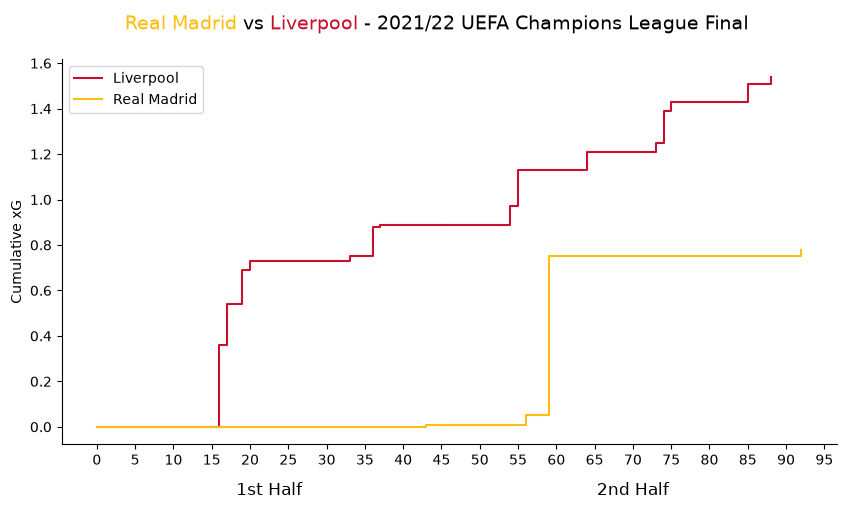

In [15]:

## 6. Suggested cleaned-up structure
liverpool_color = "#C8102E"
realmadred_color = "#FEBE10"
fig, ax = plt.subplots(figsize=(10, 5))

for team in xg_stats['Squad'].unique():
    team_df = xg_stats[xg_stats['Squad'] == team].sort_values('Minute').copy()
    team_df['Half'] = np.where(team_df['Minute'] <= 45, 1, 2)
    team_df['Cumulative_xG'] = team_df['xG'].cumsum()
    first_half = team_df[team_df['Half'] == 1]
    second_half = team_df[team_df['Half'] == 2]
    halftime_xg = first_half['Cumulative_xG'].iloc[-1] if not first_half.empty else 0

    first_half_plot = pd.concat([
        pd.DataFrame({'Minute': [0], 'Cumulative_xG': [0]}),
        first_half[['Minute', 'Cumulative_xG']],
        pd.DataFrame({'Minute': [45], 'Cumulative_xG': [halftime_xg]}),
    ], ignore_index=True)

    second_half_plot = pd.concat([
        pd.DataFrame({'Minute': [45], 'Cumulative_xG': [halftime_xg]}),
        second_half[['Minute', 'Cumulative_xG']],
    ], ignore_index=True)

    color = liverpool_color if team == 'Liverpool' else realmadred_color
    ax.plot(first_half_plot['Minute'], first_half_plot['Cumulative_xG'],
            drawstyle='steps-post', color=color, label=team)
    
    ax.plot(second_half_plot['Minute'], second_half_plot['Cumulative_xG'],
            drawstyle='steps-post', color=color)
    # Formatting and display happen once, after the loop
ax.set_xticks(range(0, 100, 5))
ax.set_yticks(np.arange(0, 1.7, 0.2))
ax.spines[['right', 'top']].set_visible(False)
ax.text(22.5, -0.3, '1st Half', ha='center', fontsize=12)
ax.text(70, -0.3, '2nd Half', ha='center', fontsize=12)
ax.set_ylabel('Cumulative xG')
fig_text(.5, .95, '<Real Madrid> vs <Liverpool> - 2021/22 UEFA Champions League Final',
         fontsize=14, ha='center', va='center', ax=ax,
         highlight_textprops=[{'color': realmadred_color}, {'color': liverpool_color}])
ax.legend()
plt.show()        
        

#### Get the stats of every team seprated to plot the xG during the match course

In [17]:
real_madrid_stats = xg_stats[xg_stats['Squad'] == 'Real Madrid']
liverpool_stats = xg_stats[xg_stats['Squad'] == 'Liverpool']

# Per-Shot xG Plot: Liverpool vs Real Madrid


## 1. What the plot shows

This is a **Scatter plot chart of the xG value of each shot** taken during the match, plotted against the minute the shot happened.

- **xG (expected goals)** is the probability that a shot becomes a goal, from 0 (almost no chance) to 1 (almost certain). Factors include distance, angle and the type of chance.
- Each point on a line is **one shot**. Its **x-position** is the match minute and its **y-position** is that shot's xG.
- There are **two lines**, one per team: Liverpool in red (`#C8102E`) and Real Madrid in gold (`#FEBE10`).

This differs from a cumulative xG chart. Here the line **does not accumulate**. A high point means a high-quality chance at that moment, and the line falls again after a low-quality chance.

## 2. How to read it

| Element | Meaning |
|---|---|
| **X-axis (Minute)** | Match minute, from 0 to 95, with a tick every 5 minutes. |
| **Y-axis (xG per shot)** | xG of a single shot, with ticks every 0.1 from 0.0 to 0.9. |
| **Red line** | Liverpool's shots in time order. |
| **Gold line** | Real Madrid's shots in time order. |
| **Peaks** | Big chances (high xG). |
| **Low points** | Speculative or low-probability shots. |
| **Gaps along the x-axis** | Long periods without a shot from that team. |

Useful questions to ask of the chart:

- **When did each team create chances?** Clusters of points show spells of pressure.
- **How good were the chances?** Higher peaks mean better chances, regardless of how many shots there were.
- **Who created the single best chance?** The highest point on either line.
- **Who shot more often?** The line with more points took more shots.

## 3. How the code works

### Step 1: Clean the minute column

```python
df["Minute"] = df["Minute"].astype(str).apply(
    lambda m: sum(int(x) for x in m.split("+"))
)
```

Shot minutes in football data can include stoppage time, such as `"90+2"`. The code splits the string on `+` and adds the parts, so `"90+2"` becomes `92` and a plain `"23"` stays `23`. This turns the column into whole numbers that can be placed on the x-axis.

### Step 2: Set colours and split by team

```python
liverpool_color = "#C8102E"
realmadred_color = "#FEBE10"

liverpool_stats = df[df["Squad"] == "Liverpool"].sort_values("Minute")
real_madrid_stats = df[df["Squad"] == "Real Madrid"].sort_values("Minute")
```

Each team's shots are filtered out of the full DataFrame and **sorted by minute**, so the line moves from left to right in time order.

### Step 3: Draw the lines

```python
ax.plot(real_madrid_stats["Minute"], real_madrid_stats["xG"], c=realmadred_color, label="Real Madrid")
ax.plot(liverpool_stats["Minute"], liverpool_stats["xG"], c=liverpool_color, label="Liverpool")
```

Each team gets one line connecting its shots in order. The `label` values feed the legend.

### Step 4: Format the chart

| Code | Effect |
|---|---|
| `set_xticks(range(0, 100, 5))` | A tick every 5 minutes. |
| `set_yticks(np.arange(0, 1, 0.1))` | Ticks from 0.0 to 0.9 in steps of 0.1. |
| `set_xlabel` / `set_ylabel` / `set_title` | Axis labels and title ("Shot xG during the match: Liverpool vs Real Madrid"). |
| `set_xlim(0, 95)` | The visible x-range is 0 to 95 minutes. |
| `grid(False)` | No grid lines. |
| `spines[...]` hidden | The top and right borders are removed for a cleaner look. |
| `legend()` | Shows which colour is which team. |


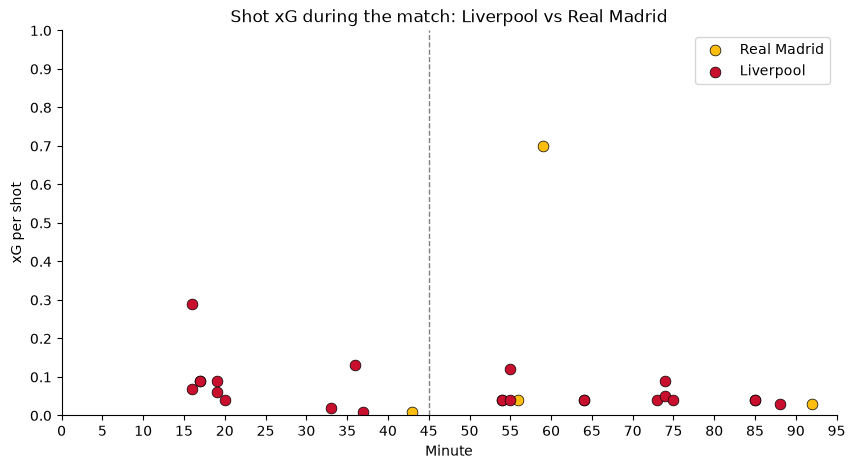

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))

for stats, color, name in [
    (real_madrid_stats, realmadred_color, "Real Madrid"),
    (liverpool_stats, liverpool_color, "Liverpool"),
]:
    ax.scatter(stats["Minute"], stats["xG"], s=60, c=color, label=name, edgecolor="black", linewidth=0.5)

ax.axvline(45, color="grey", linestyle="--", linewidth=1)   # half-time
ax.set_xticks(range(0, 100, 5))
ax.set_yticks(np.arange(0, 1.1, 0.1))
ax.set_xlim(0, 95)
ax.set_ylim(0, 1)
ax.set_xlabel("Minute")
ax.set_ylabel("xG per shot")
ax.set_title("Shot xG during the match: Liverpool vs Real Madrid")
ax.spines[["right", "top"]].set_visible(False)
ax.legend()
plt.show()